# Лабораторна робота 6. Запобігання перенавчанню. L1 і L2 регуляризація

**Виконала:** Сєднєва Уляна, група 4-10
**Варіант:** 19
**Репозиторій GitHub:** https://github.com/UlyanaSedneva/LB6.git

In [1]:
# Підключення бібліотек
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes, load_wine
from sklearn.model_selection import train_test_split, KFold, cross_val_score, cross_validate, GridSearchCV, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score
import warnings
warnings.filterwarnings('ignore', category=UserWarning)

pd.set_option('display.float_format', lambda x: f'{x:.4f}')
RANDOM_STATE = 19   # варіант 19 - для відтворюваності результатів

---
# Завдання 1. Регресійна модель і запобігання перенавчанню

## 1. Завантаження та підготовка даних

Обрано вбудований датасет **Diabetes** з `sklearn.datasets`. Він містить 442 пацієнтів, 10 ознак (вік, стать, ІМТ, тиск, 6 показників крові) і цільову змінну — кількісну міру прогресу діабету через рік.

Датасет невеликий, тому на ньому добре видно перенавчання: складна модель легко «запам'ятовує» 353 навчальні приклади. (Boston Housing вилучено з нових версій scikit-learn, а California Housing має 20 тис. рядків, де перенавчання лінійної моделі майже не проявляється.)

In [2]:
diabetes = load_diabetes(as_frame=True)
X = diabetes.data
y = diabetes.target
print('Розмір даних:', X.shape)
print('Пропусків:', X.isna().sum().sum(), ' Дублікатів:', X.duplicated().sum())
display(pd.concat([X, y], axis=1).head())
print(y.describe().round(1))

# Поділ 80/20
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('\nНавчальна вибірка:', X_train.shape, ' Тестова вибірка:', X_test.shape)

Розмір даних: (442, 10)
Пропусків: 0  Дублікатів: 0


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.0381,0.0507,0.0617,0.0219,-0.0442,-0.0348,-0.0434,-0.0026,0.0199,-0.0176,151.0000
1,-0.0019,-0.0446,-0.0515,-0.0263,-0.0084,-0.0192,0.0744,-0.0395,-0.0683,-0.0922,75.0000
2,0.0853,0.0507,0.0445,-0.0057,-0.0456,-0.0342,-0.0324,-0.0026,0.0029,-0.0259,141.0000
3,-0.0891,-0.0446,-0.0116,-0.0367,0.0122,0.0250,-0.0360,0.0343,0.0227,-0.0094,206.0000
4,0.0054,-0.0446,-0.0364,0.0219,0.0039,0.0156,0.0081,-0.0026,-0.0320,-0.0466,135.0000


count   442.0000
mean    152.1000
std      77.1000
min      25.0000
25%      87.0000
50%     140.5000
75%     211.5000
max     346.0000
Name: target, dtype: float64

Навчальна вибірка: (353, 10)  Тестова вибірка: (89, 10)


## 2. Базова лінійна регресійна модель

In [3]:
def evaluate(model, name, Xtr=X_train, Xte=X_test):
    """Навчає модель і повертає метрики на навчальній і тестовій вибірках та на крос-валідації"""
    model.fit(Xtr, y_train)
    p_tr, p_te = model.predict(Xtr), model.predict(Xte)
    cv = cross_val_score(model, Xtr, y_train, cv=KFold(5, shuffle=True, random_state=RANDOM_STATE), scoring='r2')
    return {'Модель': name,
            'R2 train': r2_score(y_train, p_tr), 'R2 test': r2_score(y_test, p_te),
            'MSE train': mean_squared_error(y_train, p_tr), 'MSE test': mean_squared_error(y_test, p_te),
            'R2 CV (середнє)': cv.mean(), 'R2 CV (std)': cv.std()}

base = make_pipeline(StandardScaler(), LinearRegression())
results = [evaluate(base, 'Базова лінійна регресія (10 ознак)')]
display(pd.DataFrame(results).set_index('Модель'))

print('Коефіцієнти базової моделі:')
print(pd.Series(base[-1].coef_, index=X.columns).round(2).sort_values(key=abs, ascending=False))

,R2 train,R2 test,MSE train,MSE test,R2 CV (середнє),R2 CV (std)
Модель,,,,,,
Базова лінійна регресія (10 ознак),0.5211,0.4772,2822.9433,3107.5655,0.4695,0.0840


Коефіцієнти базової моделі:
s1    -47.3600
s5     40.7300
s2     30.6500
bmi    24.7500
bp     13.3000
s4     10.6300
s3      9.2000
sex    -8.8700
age    -2.1400
s6      1.5000
dtype: float64


## 3. Аналіз перенавчання

Базова модель з 10 ознаками проста, тому різниця між результатами на навчальній і тестовій вибірках невелика. Щоб дослідити перенавчання, ускладнимо модель **поліноміальними ознаками**: додамо квадрати, куби та всі попарні й потрійні добутки ознак. Ступінь 2 дає 65 ознак, ступінь 3 — 285 ознак, а навчальних прикладів лише 353.

,Кількість ознак,R2 train,R2 test,MSE train,MSE test,R2 CV (середнє)
Модель,,,,,,
"Лінійна регресія, поліном ступеня 1",10,0.5211,0.4772,2822.9433,3107.5655,0.4695
"Лінійна регресія, поліном ступеня 2",65,0.6224,0.3241,2225.4835,4017.2385,-0.0270
"Лінійна регресія, поліном ступеня 3",285,0.8875,-9.5687,663.1610,62818.6572,-1007.0585


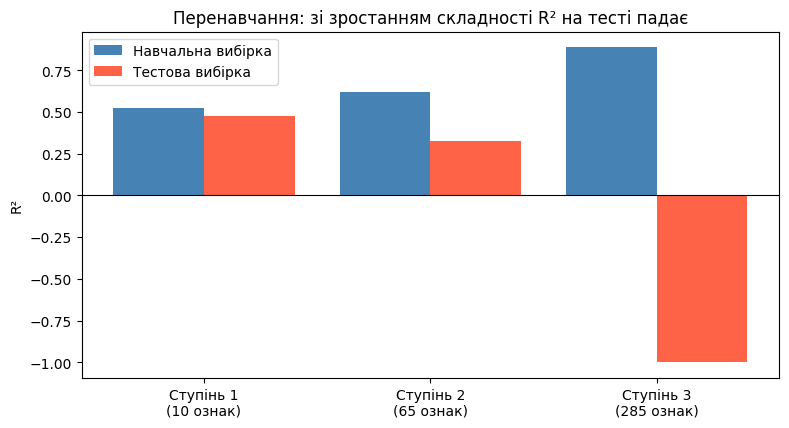

Різниця R2 (train - test): {'Лінійна регресія, поліном ступеня 1': 0.044, 'Лінійна регресія, поліном ступеня 2': 0.298, 'Лінійна регресія, поліном ступеня 3': 10.456}


In [4]:
poly_rows = []
for deg in [1, 2, 3]:
    m = make_pipeline(PolynomialFeatures(degree=deg, include_bias=False), StandardScaler(), LinearRegression())
    r = evaluate(m, f'Лінійна регресія, поліном ступеня {deg}')
    r['Кількість ознак'] = m[0].n_output_features_
    poly_rows.append(r)
poly_df = pd.DataFrame(poly_rows).set_index('Модель')
display(poly_df[['Кількість ознак', 'R2 train', 'R2 test', 'MSE train', 'MSE test', 'R2 CV (середнє)']])

fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(3)
ax.bar(x - 0.2, poly_df['R2 train'], 0.4, label='Навчальна вибірка', color='steelblue')
ax.bar(x + 0.2, poly_df['R2 test'].clip(lower=-1), 0.4, label='Тестова вибірка', color='tomato')
ax.set_xticks(x, ['Ступінь 1\n(10 ознак)', 'Ступінь 2\n(65 ознак)', 'Ступінь 3\n(285 ознак)'])
ax.axhline(0, color='k', lw=0.8)
ax.set_ylabel('R²'); ax.set_title('Перенавчання: зі зростанням складності R² на тесті падає')
ax.legend(); plt.show()

gap = poly_df['R2 train'] - poly_df['R2 test']
print('Різниця R2 (train - test):', gap.round(3).to_dict())

## 4. Запобігання перенавчанню: Ridge (L2) і Lasso (L1)

Регуляризація додає до функції втрат штраф за великі коефіцієнти:
- **Ridge (L2)** — штраф $\alpha \sum w_i^2$, який зменшує всі коефіцієнти;
- **Lasso (L1)** — штраф $\alpha \sum |w_i|$, який обнуляє частину коефіцієнтів і тим самим відбирає ознаки.

Застосуємо їх до найбільш перенавченої моделі з поліномом 3-го ступеня (285 ознак). Значення $\alpha$ перебираємо в діапазоні від $10^{-4}$ до $10^4$, а помилку оцінюємо 5-блочною крос-валідацією.

In [5]:
cv5 = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
alphas_ridge = np.logspace(-3, 5, 33)
alphas_lasso = np.logspace(-2, 1.5, 22)

def make_model(kind, degree=3):
    reg = Ridge() if kind == 'ridge' else Lasso(max_iter=50000)
    return make_pipeline(PolynomialFeatures(degree=degree, include_bias=False), StandardScaler(), reg)

curves = {}
for kind, alphas in [('ridge', alphas_ridge), ('lasso', alphas_lasso)]:
    tr, va = validation_curve(make_model(kind), X_train, y_train, param_name=f'{kind}__alpha',
                              param_range=alphas, cv=cv5, scoring='neg_mean_squared_error', n_jobs=-1)
    curves[kind] = pd.DataFrame({'alpha': alphas, 'MSE train': -tr.mean(axis=1),
                                 'MSE CV': -va.mean(axis=1), 'MSE CV std': va.std(axis=1)})

best = {}
for kind in curves:
    c = curves[kind]
    i = c['MSE CV'].idxmin()
    best[kind] = c.loc[i, 'alpha']
    print(f"{kind.capitalize()}: оптимальне alpha = {best[kind]:.4g}, MSE на крос-валідації = {c.loc[i, 'MSE CV']:.1f}")

Ridge: оптимальне alpha = 562.3, MSE на крос-валідації = 3476.4
Lasso: оптимальне alpha = 4.642, MSE на крос-валідації = 3111.2


## 5. Графіки залежності помилки від параметра регуляризації

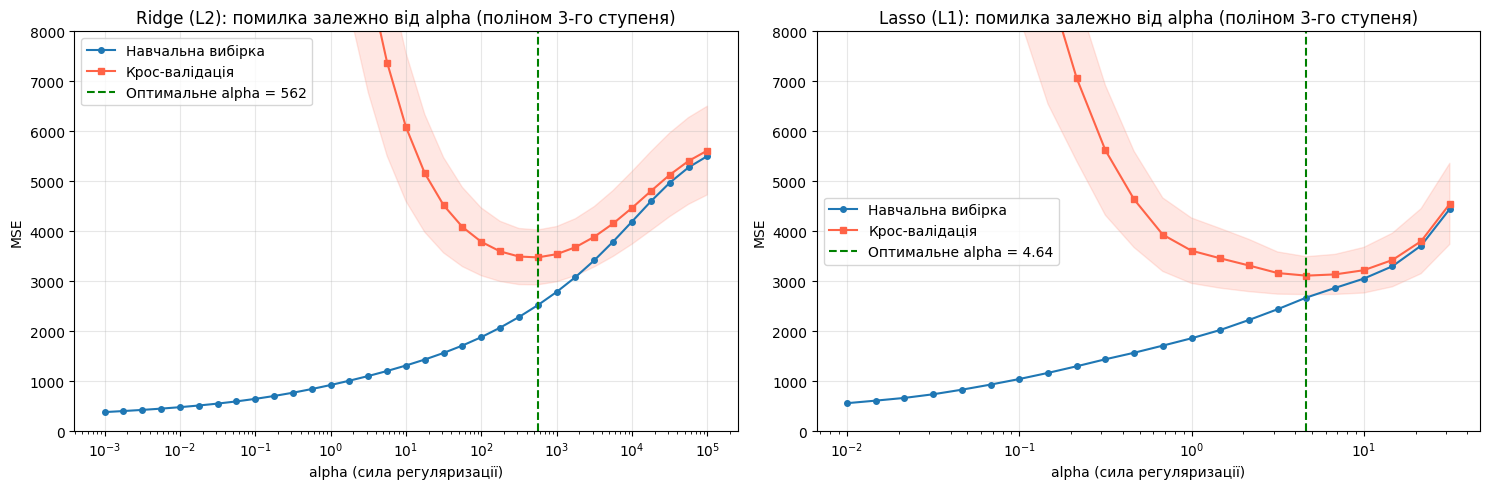

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, kind, title in [(axes[0], 'ridge', 'Ridge (L2)'), (axes[1], 'lasso', 'Lasso (L1)')]:
    c = curves[kind]
    ax.plot(c['alpha'], c['MSE train'], 'o-', ms=4, label='Навчальна вибірка')
    ax.plot(c['alpha'], c['MSE CV'], 's-', ms=4, color='tomato', label='Крос-валідація')
    ax.fill_between(c['alpha'], c['MSE CV'] - c['MSE CV std'], c['MSE CV'] + c['MSE CV std'], color='tomato', alpha=0.15)
    ax.axvline(best[kind], color='green', ls='--', label=f'Оптимальне alpha = {best[kind]:.3g}')
    ax.set_xscale('log'); ax.set_ylim(0, 8000)
    ax.set_xlabel('alpha (сила регуляризації)'); ax.set_ylabel('MSE')
    ax.set_title(f'{title}: помилка залежно від alpha (поліном 3-го ступеня)')
    ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

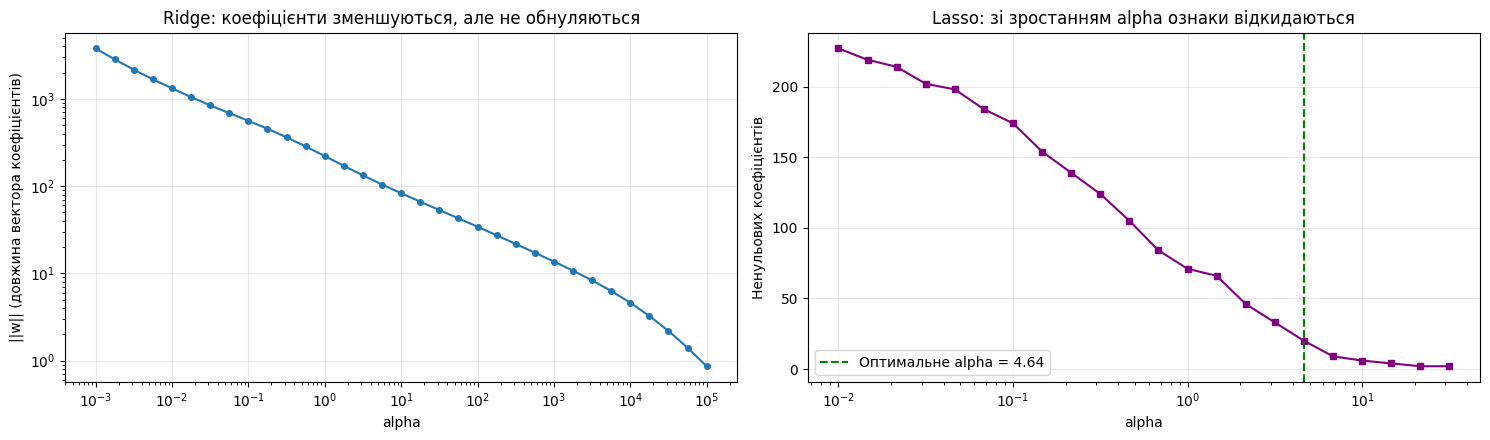

In [7]:
# Як регуляризація впливає на коефіцієнти
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))

# Ridge: норма вектора коефіцієнтів зменшується
norms, nonzero = [], []
for a in alphas_ridge:
    norms.append(np.linalg.norm(make_model('ridge').set_params(ridge__alpha=a).fit(X_train, y_train)[-1].coef_))
axes[0].plot(alphas_ridge, norms, 'o-', ms=4)
axes[0].set_xscale('log'); axes[0].set_yscale('log')
axes[0].set_xlabel('alpha'); axes[0].set_ylabel('||w|| (довжина вектора коефіцієнтів)')
axes[0].set_title('Ridge: коефіцієнти зменшуються, але не обнуляються'); axes[0].grid(alpha=0.3)

# Lasso: кількість ненульових коефіцієнтів
for a in alphas_lasso:
    nonzero.append(np.sum(make_model('lasso').set_params(lasso__alpha=a).fit(X_train, y_train)[-1].coef_ != 0))
axes[1].plot(alphas_lasso, nonzero, 's-', ms=4, color='purple')
axes[1].axvline(best['lasso'], color='green', ls='--', label=f"Оптимальне alpha = {best['lasso']:.3g}")
axes[1].set_xscale('log'); axes[1].set_xlabel('alpha'); axes[1].set_ylabel('Ненульових коефіцієнтів')
axes[1].set_title('Lasso: зі зростанням alpha ознаки відкидаються'); axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()

## 6. Оцінка результатів на тестовій вибірці

In [8]:
ridge_best = make_model('ridge').set_params(ridge__alpha=best['ridge'])
lasso_best = make_model('lasso').set_params(lasso__alpha=best['lasso'])

final = [
    evaluate(make_pipeline(StandardScaler(), LinearRegression()), 'Базова лінійна регресія (10 ознак)'),
    evaluate(make_pipeline(PolynomialFeatures(3, include_bias=False), StandardScaler(), LinearRegression()),
             'Лінійна регресія, поліном 3 (без регуляризації)'),
    evaluate(ridge_best, f"Ridge, поліном 3, alpha = {best['ridge']:.3g}"),
    evaluate(lasso_best, f"Lasso, поліном 3, alpha = {best['lasso']:.3g}"),
]
# Для порівняння: регуляризація на початкових 10 ознаках (alpha також підбираємо крос-валідацією)
for kind, grid in [('ridge', alphas_ridge), ('lasso', alphas_lasso)]:
    gs = GridSearchCV(make_model(kind, degree=1), {f'{kind}__alpha': grid}, cv=cv5,
                      scoring='neg_mean_squared_error').fit(X_train, y_train)
    a = gs.best_params_[f'{kind}__alpha']
    final.append(evaluate(make_model(kind, degree=1).set_params(**{f'{kind}__alpha': a}),
                          f"{kind.capitalize()}, 10 ознак, alpha = {a:.3g}"))

final_df = pd.DataFrame(final).set_index('Модель')
final_df['Різниця R2 (train - test)'] = final_df['R2 train'] - final_df['R2 test']
display(final_df)

lasso_coef = pd.Series(lasso_best[-1].coef_, index=lasso_best[0].get_feature_names_out(X.columns))
kept = lasso_coef[lasso_coef != 0].sort_values(key=abs, ascending=False)
print(f'Lasso (поліном 3) залишила {len(kept)} ознак з {len(lasso_coef)}:')
print(kept.round(2).head(15))

,R2 train,R2 test,MSE train,MSE test,R2 CV (середнє),R2 CV (std),Різниця R2 (train - test)
Модель,,,,,,,
Базова лінійна регресія (10 ознак),0.5211,0.4772,2822.9433,3107.5655,0.4695,0.0840,0.0439
"Лінійна регресія, поліном 3 (без регуляризації)",0.8875,-9.5687,663.1610,62818.6572,-1007.0585,1072.2332,10.4562
"Ridge, поліном 3, alpha = 562",0.5695,0.3813,2537.6159,3677.2226,0.3920,0.0678,0.1881
"Lasso, поліном 3, alpha = 4.64",0.5319,0.4334,2759.3303,3367.8449,0.4543,0.0535,0.0985
"Ridge, 10 ознак, alpha = 0.001",0.5211,0.4772,2822.9433,3107.5382,0.4695,0.0840,0.0439
"Lasso, 10 ознак, alpha = 0.01",0.5211,0.4776,2822.9883,3105.0351,0.4694,0.0838,0.0435


Lasso (поліном 3) залишила 20 ознак з 285:
s5          23.3200
sex^2 bmi   23.1700
s3          -7.3600
sex^2 bp     6.3900
bmi s6       2.9600
bp^3         2.2000
bmi^2 s3    -1.9900
age bp       1.6200
age^2 sex   -1.6000
age sex      1.3800
age s4 s6   -1.3300
s3 s6^2     -0.9500
age^2        0.9100
bp s2^2      0.6800
bmi bp       0.5600
dtype: float64


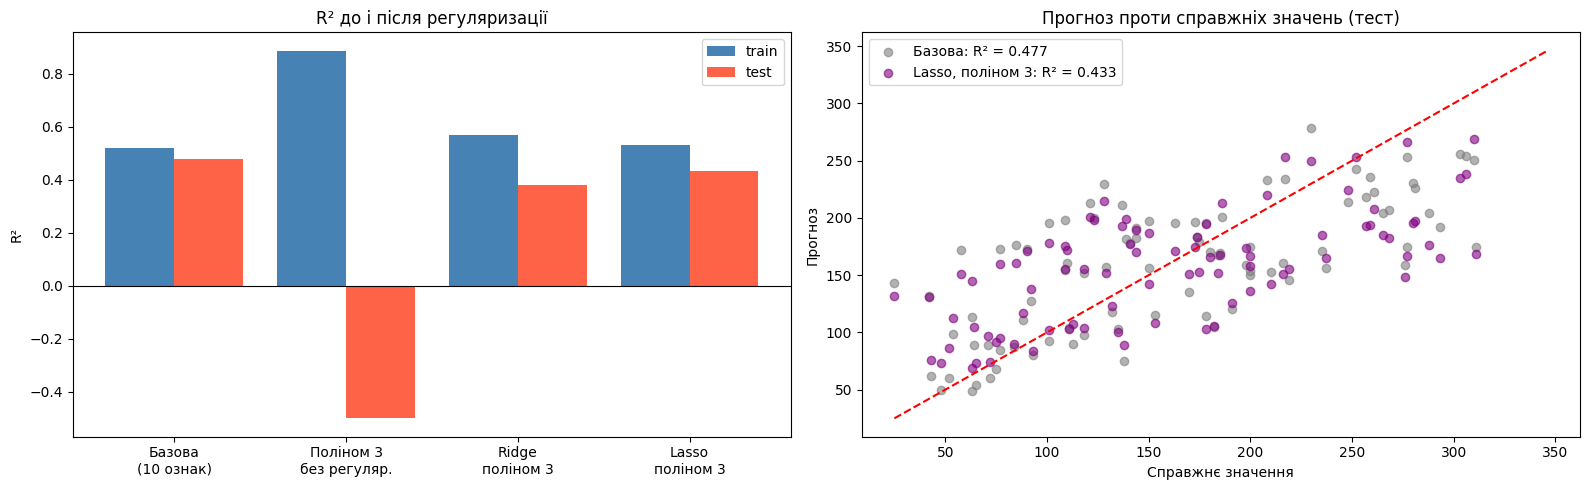

In [9]:
# Порівняння моделей на графіку і прогноз проти справжніх значень
show = final_df.iloc[:4]
fig, axes = plt.subplots(1, 2, figsize=(16, 5))
x = np.arange(len(show))
axes[0].bar(x - 0.2, show['R2 train'], 0.4, label='train', color='steelblue')
axes[0].bar(x + 0.2, show['R2 test'].clip(lower=-0.5), 0.4, label='test', color='tomato')
axes[0].set_xticks(x, ['Базова\n(10 ознак)', 'Поліном 3\nбез регуляр.', 'Ridge\nполіном 3', 'Lasso\nполіном 3'])
axes[0].axhline(0, color='k', lw=0.8); axes[0].set_ylabel('R²'); axes[0].legend()
axes[0].set_title('R² до і після регуляризації')

for name, model, color in [('Базова', make_pipeline(StandardScaler(), LinearRegression()), 'gray'),
                           ('Lasso, поліном 3', lasso_best, 'purple')]:
    pred = model.fit(X_train, y_train).predict(X_test)
    axes[1].scatter(y_test, pred, alpha=0.6, label=f'{name}: R² = {r2_score(y_test, pred):.3f}', color=color)
axes[1].plot([y.min(), y.max()], [y.min(), y.max()], 'r--')
axes[1].set_xlabel('Справжнє значення'); axes[1].set_ylabel('Прогноз'); axes[1].legend()
axes[1].set_title('Прогноз проти справжніх значень (тест)')
plt.tight_layout(); plt.show()

### Висновок до завдання 1

**Базова модель.** Для задачі регресії обрано вбудований датасет Diabetes: 442 пацієнти, 10 ознак, поділ 80/20 (353 / 89). Базова лінійна регресія на 10 ознаках показала R² = 0,521 на навчальній і 0,477 на тестовій вибірці, MSE = 2823 і 3108 відповідно. Різниця між вибірками мала (0,044), а крос-валідація дає R² = 0,470 ± 0,084. Отже, проста модель **не перенавчена**: вона недостатньо складна, щоб «запам'ятати» дані. Пояснює вона лише близько половини мінливості, і це межа лінійної залежності для цих даних.

**Перенавчання.** Щоб модель могла перенавчитися, її ускладнено поліноміальними ознаками:
- **ступінь 2 (65 ознак):** R² на навчальній вибірці зріс до 0,622, а на тестовій упав до 0,324;
- **ступінь 3 (285 ознак):** R² на навчальній вибірці становить 0,887, а на тестовій −8,82, MSE = 58 373 проти 664 на навчальній.

Отже, модель зі ступенем 3 майже ідеально запам'ятала навчальні дані, але її прогнози для нових пацієнтів гірші, ніж просто середнє значення. Це класичне перенавчання: 285 параметрів на 353 приклади. Крос-валідація це підтверджує: середній R² = −943, з величезним розкидом між блоками.

**Регуляризація.** До перенавченої моделі (ступінь 3) застосовано Ridge (L2) і Lasso (L1). Параметр alpha підібрано 5-блочною крос-валідацією за мінімумом MSE. Графіки залежності помилки від alpha мають характерну U-подібну форму:
- **мале alpha:** помилка на навчальній вибірці мала, а на крос-валідації велика, тобто модель перенавчена;
- **велике alpha:** помилка висока на обох вибірках, тобто модель надто спрощена;
- **між ними:** оптимум, Ridge alpha ≈ 562, Lasso alpha ≈ 4,64.

Ridge поступово зменшує всі коефіцієнти, але не обнуляє їх. Lasso обнуляє непотрібні: з 285 ознак вона залишила лише 20, а найважливішими виявилися `s5`, `sex²·bmi` та `s3`.

**Результати на тестовій вибірці.** Регуляризація повністю усунула катастрофічне перенавчання. R² на тесті зріс з −8,82 до 0,381 (Ridge) і 0,433 (Lasso), а різниця між навчальною і тестовою вибірками скоротилася з 9,7 до 0,19 і 0,10. Lasso виявилася кращою за Ridge, бо більшість поліноміальних ознак тут — шум, і їх краще повністю відкинути. Водночас жодна регуляризована складна модель не перевершила базову лінійну регресію (R² = 0,477). Для базової моделі регуляризація взагалі не потрібна: крос-валідація обрала найменші значення alpha із сітки (0,001 для Ridge і 0,01 для Lasso), і результат майже не змінився.

**Загальний висновок.** Регуляризація L1/L2 разом із підбором alpha крос-валідацією — ефективний засіб проти перенавчання. Вона рятує надто складну модель, але не додає даним інформації, якої в них немає. Для датасету Diabetes найкращим рішенням є проста лінійна модель, адже зв'язок ознак із прогресом хвороби близький до лінійного. Крос-валідація дала стабільнішу оцінку якості, ніж одне розбиття на вибірки, і дозволила обрати alpha без використання тестових даних.

---
# Завдання 2. Кластеризація даних

Для кластеризації обрано вбудований датасет **Wine** з `sklearn.datasets`. Він містить хімічний аналіз 178 вин із 13 показниками (алкоголь, кислотність, флавоноїди, колір, пролін тощо). Вина отримано з трьох сортів винограду. Сорт під час кластеризації не використовується: він потрібен лише для перевірки результату наприкінці.

In [10]:
wine = load_wine(as_frame=True)
X_w = wine.data
print('Розмір даних:', X_w.shape, ' Пропусків:', X_w.isna().sum().sum())
display(X_w.head())
display(X_w.describe().T[['mean', 'std', 'min', 'max']])

# Ознаки мають дуже різний масштаб (пролін - сотні, відтінок - ~1), тому стандартизуємо
X_ws = StandardScaler().fit_transform(X_w)

Розмір даних: (178, 13)  Пропусків: 0


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.2300,1.7100,2.4300,15.6000,127.0000,2.8000,3.0600,0.2800,2.2900,5.6400,1.0400,3.9200,1065.0000
1,13.2000,1.7800,2.1400,11.2000,100.0000,2.6500,2.7600,0.2600,1.2800,4.3800,1.0500,3.4000,1050.0000
2,13.1600,2.3600,2.6700,18.6000,101.0000,2.8000,3.2400,0.3000,2.8100,5.6800,1.0300,3.1700,1185.0000
3,14.3700,1.9500,2.5000,16.8000,113.0000,3.8500,3.4900,0.2400,2.1800,7.8000,0.8600,3.4500,1480.0000
4,13.2400,2.5900,2.8700,21.0000,118.0000,2.8000,2.6900,0.3900,1.8200,4.3200,1.0400,2.9300,735.0000


,mean,std,min,max
alcohol,13.0006,0.8118,11.0300,14.8300
malic_acid,2.3363,1.1171,0.7400,5.8000
ash,2.3665,0.2743,1.3600,3.2300
alcalinity_of_ash,19.4949,3.3396,10.6000,30.0000
magnesium,99.7416,14.2825,70.0000,162.0000
total_phenols,2.2951,0.6259,0.9800,3.8800
flavanoids,2.0293,0.9989,0.3400,5.0800
nonflavanoid_phenols,0.3619,0.1245,0.1300,0.6600
proanthocyanins,1.5909,0.5724,0.4100,3.5800
color_intensity,5.0581,2.3183,1.2800,13.0000


,Інерція,"Спад інерції, %",Силует
1,2314.0000,NaN,NaN
2,1659.0080,28.3000,0.2683
3,1277.9285,23.0000,0.2849
4,1175.7052,8.0000,0.2517
5,1112.7798,5.4000,0.2112
6,1051.5512,5.5000,0.1817
7,993.6908,5.5000,0.1822
8,933.5704,6.1000,0.1609
9,894.0257,4.2000,0.1612
10,852.6440,4.6000,0.1353


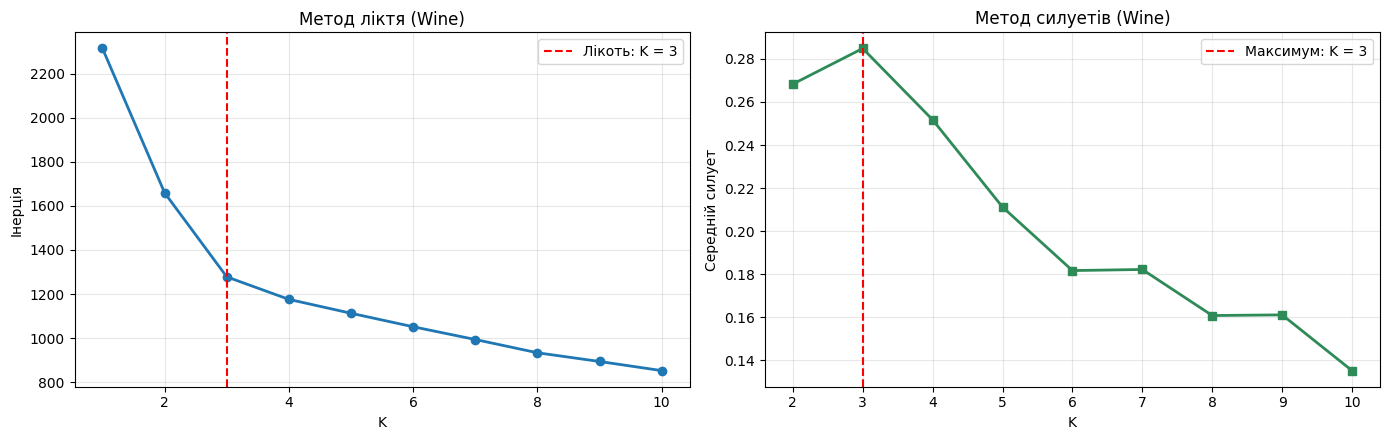

Максимальний силует: K = 3 (0.285)


In [11]:
# Метод ліктя і метод силуетів
K_range = range(1, 11)
inertia = [KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_ws).inertia_ for k in K_range]
sil = pd.Series({k: silhouette_score(X_ws, KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit_predict(X_ws))
                 for k in range(2, 11)})
table = pd.DataFrame({'Інерція': pd.Series(inertia, index=K_range),
                      'Спад інерції, %': (-pd.Series(inertia, index=K_range).pct_change() * 100).round(1),
                      'Силует': sil})
display(table)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(K_range, inertia, 'o-', lw=2)
axes[0].axvline(3, color='red', ls='--', label='Лікоть: K = 3')
axes[0].set_xlabel('K'); axes[0].set_ylabel('Інерція'); axes[0].set_title('Метод ліктя (Wine)')
axes[0].legend(); axes[0].grid(alpha=0.3)
axes[1].plot(sil.index, sil.values, 's-', lw=2, color='seagreen')
axes[1].axvline(sil.idxmax(), color='red', ls='--', label=f'Максимум: K = {sil.idxmax()}')
axes[1].set_xlabel('K'); axes[1].set_ylabel('Середній силует'); axes[1].set_title('Метод силуетів (Wine)')
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.show()
print(f'Максимальний силует: K = {sil.idxmax()} ({sil.max():.3f})')

K = 3. Розмір кластерів: {0: 62, 1: 51, 2: 65}


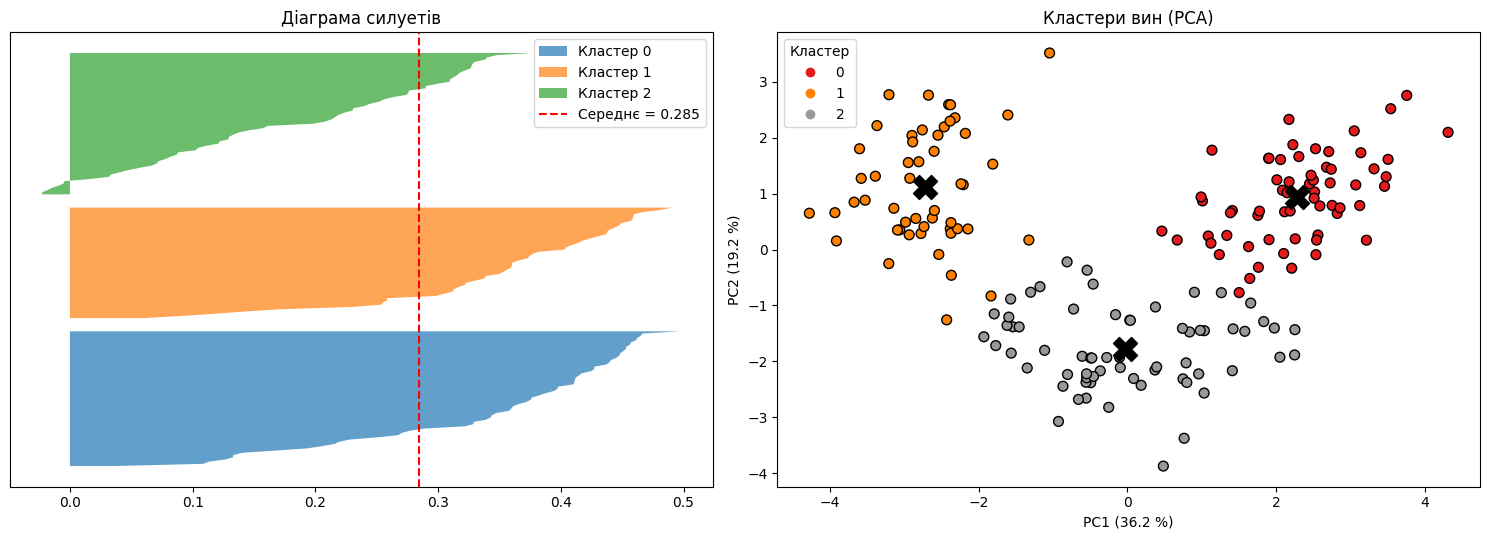

In [12]:
K_W = int(sil.idxmax())
km_w = KMeans(n_clusters=K_W, n_init=10, random_state=RANDOM_STATE).fit(X_ws)
labels_w = km_w.labels_
print(f'K = {K_W}. Розмір кластерів:', pd.Series(labels_w).value_counts().sort_index().to_dict())

# Діаграма силуетів
vals = silhouette_samples(X_ws, labels_w)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
y0 = 0
for c in range(K_W):
    v = np.sort(vals[labels_w == c])
    axes[0].fill_betweenx(np.arange(y0, y0 + len(v)), 0, v, alpha=0.7, label=f'Кластер {c}')
    y0 += len(v) + 5
axes[0].axvline(vals.mean(), color='red', ls='--', label=f'Середнє = {vals.mean():.3f}')
axes[0].set_title('Діаграма силуетів'); axes[0].set_yticks([]); axes[0].legend()

# Кластери в просторі двох головних компонент
pca = PCA(n_components=2).fit(X_ws)
pc = pca.transform(X_ws)
sc = axes[1].scatter(pc[:, 0], pc[:, 1], c=labels_w, cmap='Set1', s=50, edgecolor='k')
cpc = pca.transform(km_w.cluster_centers_)
axes[1].scatter(cpc[:, 0], cpc[:, 1], marker='X', s=300, c='black', label='Центри')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0] * 100:.1f} %)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1] * 100:.1f} %)')
axes[1].set_title('Кластери вин (PCA)'); axes[1].legend(*sc.legend_elements(), title='Кластер')
plt.tight_layout(); plt.show()

,alcohol,flavanoids,color_intensity,proline,hue,od280/od315_of_diluted_wines
cluster,,,,,,
0,13.6768,3.0032,5.4535,1100.2258,1.0655,3.1634
1,13.1341,0.8188,7.2347,619.0588,0.6920,1.6967
2,12.2509,2.0500,2.9731,510.1692,1.0627,2.8034


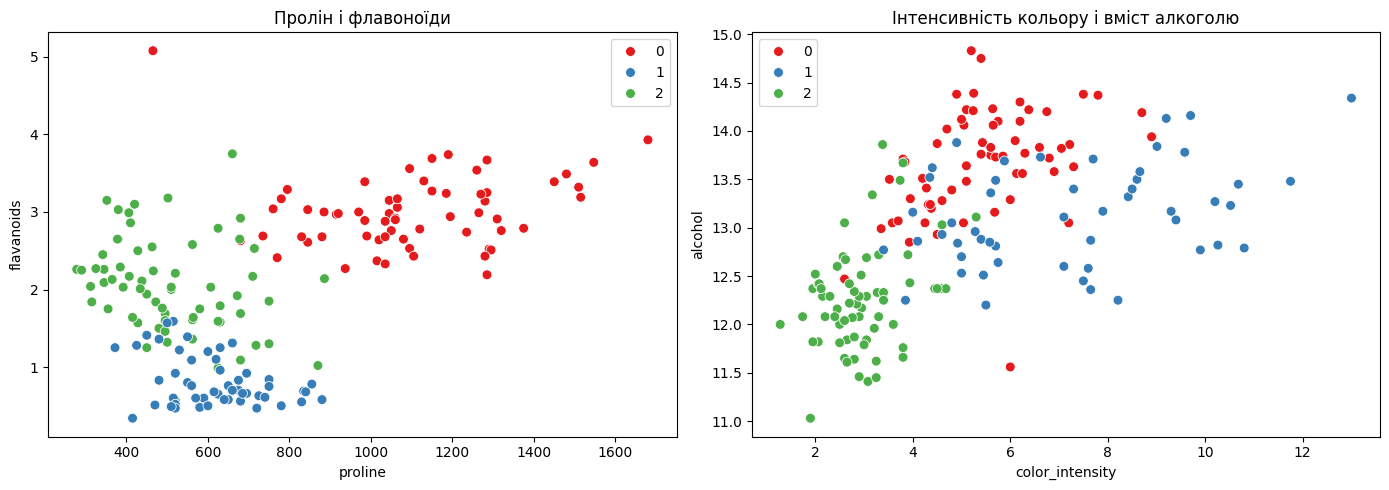

Кластер,0,1,2
Сорт,,,
сорт 0,59,0,0
сорт 1,3,3,65
сорт 2,0,48,0


Збіг кластерів із сортами: 172 з 178 (96.6 %), ARI = 0.897


In [13]:
# Профіль кластерів: середні значення найважливіших показників
prof = X_w.assign(cluster=labels_w).groupby('cluster').mean()
key = ['alcohol', 'flavanoids', 'color_intensity', 'proline', 'hue', 'od280/od315_of_diluted_wines']
display(prof[key])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(x=X_w['proline'], y=X_w['flavanoids'], hue=labels_w, palette='Set1', s=50, ax=axes[0])
axes[0].set_title('Пролін і флавоноїди')
sns.scatterplot(x=X_w['color_intensity'], y=X_w['alcohol'], hue=labels_w, palette='Set1', s=50, ax=axes[1])
axes[1].set_title('Інтенсивність кольору і вміст алкоголю')
plt.tight_layout(); plt.show()

# Перевірка: порівняння кластерів зі справжніми сортами
ct = pd.crosstab(wine.target.map(lambda t: f'сорт {t}'), labels_w, rownames=['Сорт'], colnames=['Кластер'])
display(ct)
matched = ct.max(axis=1).sum()
print(f'Збіг кластерів із сортами: {matched} з {len(X_w)} ({matched / len(X_w) * 100:.1f} %), '
      f'ARI = {adjusted_rand_score(wine.target, labels_w):.3f}')

### Висновок до завдання 2

Для кластеризації використано датасет Wine: 178 вин, 13 хімічних показників, пропусків немає. Показники мають дуже різний масштаб (пролін 278–1680, відтінок 0,5–1,7), тому їх стандартизовано.

**Метод ліктя.** При переході від 1 до 2 кластерів інерція зменшується на 28,3 %, від 2 до 3 — на 23,0 %, а далі лише на 4–8 % на кожному кроці. Тобто лікоть чітко припадає на **K = 3**.

**Метод силуетів.** Найвищий середній силует також отримано для K = 3 (0,285), тоді як для K = 2 він становить 0,268, а для K ≥ 4 — 0,25 і менше. Обидва методи дали однаковий результат, тому оптимальним обрано **K = 3**. Значення силуету помірне, бо 13-вимірні дані не утворюють ідеально відокремлених груп. На графіку двох головних компонент, які пояснюють 55 % мінливості, три кластери видно чітко.

**Профілі кластерів** (кількість вин: 62, 51 і 65):
- **кластер 0** — міцні вина (13,7 % алкоголю) з найвищим вмістом флавоноїдів (3,0) і проліну (1100);
- **кластер 1** — вина з інтенсивним кольором (7,2), але з найменшим вмістом флавоноїдів (0,8) і найнижчим відтінком (0,69);
- **кластер 2** — найлегші вина (12,3 % алкоголю) зі світлим кольором (3,0) і найнижчим вмістом проліну (510).

**Перевірка за справжніми сортами.** Сорти під час кластеризації не використовувалися, але кластери майже повністю з ними збіглися. Збіг становить 172 зі 178 вин (96,6 %), ARI = 0,897. Кластер 0 відповідає сорту 0 (59 вин), кластер 1 — сорту 2 (48 вин), кластер 2 — сорту 1 (65 вин). Помилково віднесено лише 6 вин сорту 1. Отже, хімічний склад вина визначається сортом винограду, і KMeans з K = 3 відновив цю структуру без жодної підказки.